# EDA Retail Business Analysis
## Case Study: Retail Sales Dataset

**Project basis:** The provided `EDA Retail Business Analysis CASE STUDY` PDF and the supplied e-commerce sales CSV.

### Business problem
The business wants to understand which products sell more, which regions generate more profit, how discounts relate to profit, and how customers prefer to pay.

### Objectives
- Understand the dataset and validate its quality.
- Clean only issues supported by the data.
- Answer the data manipulation questions from the case study.
- Create univariate, bivariate, and multivariate visualizations that support the required questions.
- Summarize evidence-based insights and practical recommendations.

**Scope note:** The CSV filename says 2024–2025, but the actual data includes orders from 2023-10-04 through 2025-10-03. Records are retained rather than removed based on the filename. No statistical hypothesis tests are added because the case-study instructions do not require them.

## 1. Imports and Dataset Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

# Keep the original CSV in the same folder as this notebook.
file_path = "Ecommerce_Sales_Data_2024_2025 (1).csv"
df_raw = pd.read_csv(file_path)

print("Dataset name:", file_path)
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
display(df_raw.head())

Dataset name: Ecommerce_Sales_Data_2024_2025 (1).csv
Rows: 5000
Columns: 14


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
0,10001,2024-10-19,Kashvi Varty,South,Bangalore,Books,Non-Fiction,Non-Fiction Ipsum,2,36294,5,68958.6,10525.09,Debit Card
1,10002,2025-08-30,Advik Desai,North,Delhi,Groceries,Rice,Rice Nemo,1,42165,20,33732.0,6299.66,Debit Card
2,10003,2023-11-04,Rhea Kalla,East,Patna,Kitchen,Juicer,Juicer Odio,4,64876,20,207603.2,19850.27,Credit Card
3,10004,2025-05-23,Anika Sen,East,Kolkata,Groceries,Oil,Oil Doloribus,5,37320,15,158610.0,36311.02,UPI
4,10005,2025-01-19,Akarsh Kaul,West,Pune,Clothing,Kids Wear,Kids Wear Quo,1,50037,10,45033.3,9050.04,Debit Card


## 2. Data Understanding

### Question: What are the dataset dimensions, column names, and data types?

In [2]:
print("Shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types:")
display(df_raw.dtypes.rename("Data Type").to_frame())

Shape: (5000, 14)

Column names:
['Order ID', 'Order Date', 'Customer Name', 'Region', 'City', 'Category', 'Sub-Category', 'Product Name', 'Quantity', 'Unit Price', 'Discount', 'Sales', 'Profit', 'Payment Mode']

Data types:


,Data Type
Order ID,int64
Order Date,object
Customer Name,object
Region,object
City,object
Category,object
Sub-Category,object
Product Name,object
Quantity,int64
Unit Price,int64


**Observation:** This cell reports the actual structure of the supplied dataset rather than assuming columns from the case-study example.

### Question: What are the first and last five orders?

In [3]:
print("First five orders")
display(df_raw.head())
print("Last five orders")
display(df_raw.tail())

First five orders


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
0,10001,2024-10-19,Kashvi Varty,South,Bangalore,Books,Non-Fiction,Non-Fiction Ipsum,2,36294,5,68958.6,10525.09,Debit Card
1,10002,2025-08-30,Advik Desai,North,Delhi,Groceries,Rice,Rice Nemo,1,42165,20,33732.0,6299.66,Debit Card
2,10003,2023-11-04,Rhea Kalla,East,Patna,Kitchen,Juicer,Juicer Odio,4,64876,20,207603.2,19850.27,Credit Card
3,10004,2025-05-23,Anika Sen,East,Kolkata,Groceries,Oil,Oil Doloribus,5,37320,15,158610.0,36311.02,UPI
4,10005,2025-01-19,Akarsh Kaul,West,Pune,Clothing,Kids Wear,Kids Wear Quo,1,50037,10,45033.3,9050.04,Debit Card


Last five orders


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
4995,14996,2024-06-25,Nishith Kulkarni,East,Kolkata,Books,Fiction,Fiction Veritatis,3,60671,0,182013.0,11853.15,Debit Card
4996,14997,2024-12-22,Aaina Chander,North,Jaipur,Toys,Doll,Doll Nulla,5,70048,0,350240.0,31237.23,Credit Card
4997,14998,2025-04-15,Dhanush Gara,South,Bangalore,Beauty,Lipstick,Lipstick Eaque,1,42162,15,35837.7,7827.50,Debit Card
4998,14999,2024-07-08,Divyansh Malhotra,East,Kolkata,Electronics,Smartwatch,Smartwatch Adipisci,4,13568,10,48844.8,6603.86,Credit Card
4999,15000,2024-02-04,Aarush Walla,West,Goa,Clothing,Kids Wear,Kids Wear Repellat,1,76762,10,69085.8,5785.85,Net Banking


### Question: What is the first and last order date?

In [4]:
dates_for_check = pd.to_datetime(df_raw["Order Date"], errors="coerce")
print("Earliest order date:", dates_for_check.min())
print("Latest order date:", dates_for_check.max())
print("Unparseable dates:", dates_for_check.isna().sum())

Earliest order date: 2023-10-04 00:00:00
Latest order date: 2025-10-03 00:00:00
Unparseable dates: 0


### Question: What regions, categories, and payment methods are present?

In [5]:
for column in ["Region", "Category", "Payment Mode"]:
    print(f"\n{column} ({df_raw[column].nunique(dropna=False)} distinct values)")
    print(sorted(df_raw[column].dropna().astype(str).unique()))


Region (4 distinct values)
['East', 'North', 'South', 'West']

Category (10 distinct values)
['Beauty', 'Books', 'Clothing', 'Electronics', 'Furniture', 'Groceries', 'Home Decor', 'Kitchen', 'Sports', 'Toys']

Payment Mode (5 distinct values)
['COD', 'Credit Card', 'Debit Card', 'Net Banking', 'UPI']


### Question: Which columns are numeric and which are text?

In [6]:
numeric_columns = df_raw.select_dtypes(include="number").columns.tolist()
text_columns = df_raw.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print("Numeric columns:", numeric_columns)
print("Text/categorical columns:", text_columns)

Numeric columns: ['Order ID', 'Quantity', 'Unit Price', 'Discount', 'Sales', 'Profit']
Text/categorical columns: ['Order Date', 'Customer Name', 'Region', 'City', 'Category', 'Sub-Category', 'Product Name', 'Payment Mode']


### Question: What do the summary statistics show?

In [7]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order ID,5000.0,NaN,NaN,NaN,12500.5,1443.520003,10001.0,11250.75,12500.5,13750.25,15000.0
Order Date,5000,730,2025-09-15,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,5000,4844,Vritika Cherian,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,5000,4,North,1288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,5000,20,Guwahati,293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,5000,10,Books,528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-Category,5000,50,Sofa,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Name,5000,3835,Chair Adipisci,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,5000.0,NaN,NaN,NaN,2.9926,1.413133,1.0,2.0,3.0,4.0,5.0
Unit Price,5000.0,NaN,NaN,NaN,39760.9046,22831.783946,222.0,20312.25,39459.5,59721.75,79998.0


## 3. Data Cleaning and Preparation

### Cleaning decisions
- Convert `Order Date` to a real datetime type.
- Remove leading/trailing whitespace from text fields if present.
- Check missing values, full-row duplicates, duplicate order IDs, invalid quantity/discount/sales/profit values, and category consistency.
- Do not drop rows or impute values unless a specific issue is found and a defensible action is necessary.

### Question: Are there missing values or duplicate records?

In [8]:
print("Missing values by column:")
display(df_raw.isna().sum().rename("Missing Count").to_frame())
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate Order IDs:", df_raw["Order ID"].duplicated().sum())

Missing values by column:


,Missing Count
Order ID,0
Order Date,0
Customer Name,0
Region,0
City,0
Category,0
Sub-Category,0
Product Name,0
Quantity,0
Unit Price,0


Exact duplicate rows: 0
Duplicate Order IDs: 0


### Question: Is the order date valid, and are quantity, discount, sales, and profit values reasonable?

In [9]:
df = df_raw.copy()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Unparseable dates:", df["Order Date"].isna().sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Discount < 0:", (df["Discount"] < 0).sum())
print("Discount > 100:", (df["Discount"] > 100).sum())
print("Sales < 0:", (df["Sales"] < 0).sum())
print("Profit < 0:", (df["Profit"] < 0).sum())

Unparseable dates: 0
Quantity <= 0: 0
Discount < 0: 0
Discount > 100: 0
Sales < 0: 0
Profit < 0: 0


### Question: Are text values affected by leading/trailing spaces?

In [10]:
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
space_report = {
    col: int((df[col].notna() & (df[col] != df[col].str.strip())).sum())
    for col in text_cols
}
display(pd.Series(space_report, name="Values with surrounding whitespace").to_frame())

,Values with surrounding whitespace
Customer Name,0
Region,0
City,0
Category,0
Sub-Category,0
Product Name,0
Payment Mode,0


### Cleaning implementation

In [11]:
# Apply only non-destructive cleaning supported by the checks.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Re-parse the date after text cleanup. Invalid dates remain missing and are reported.
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Rows before cleaning:", len(df_raw))
print("Rows after cleaning:", len(df))
print("Columns before cleaning:", df_raw.shape[1])
print("Columns after cleaning:", df.shape[1])

Rows before cleaning: 5000
Rows after cleaning: 5000
Columns before cleaning: 14
Columns after cleaning: 14


## 4. Data Validation

### Question: Does the cleaned dataset pass the core validation checks?

In [12]:
validation = pd.DataFrame({
    "Check": [
        "Row count preserved",
        "Column count preserved",
        "Missing values",
        "Exact duplicate rows",
        "Duplicate Order IDs",
        "Unparseable order dates",
        "Quantity <= 0",
        "Discount outside 0-100",
        "Negative sales",
        "Negative profit"
    ],
    "Result": [
        len(df) == len(df_raw),
        df.shape[1] == df_raw.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["Order ID"].duplicated().sum()),
        int(df["Order Date"].isna().sum()),
        int((df["Quantity"] <= 0).sum()),
        int(((df["Discount"] < 0) | (df["Discount"] > 100)).sum()),
        int((df["Sales"] < 0).sum()),
        int((df["Profit"] < 0).sum())
    ]
})
display(validation)

,Check,Result
0,Row count preserved,True
1,Column count preserved,True
2,Missing values,0
3,Exact duplicate rows,0
4,Duplicate Order IDs,0
5,Unparseable order dates,0
6,Quantity <= 0,0
7,Discount outside 0-100,0
8,Negative sales,0
9,Negative profit,0


### Question: Do recorded sales match quantity, unit price, and discount?

In [13]:
expected_sales = df["Quantity"] * df["Unit Price"] * (1 - df["Discount"] / 100)
sales_difference = (df["Sales"] - expected_sales).abs()
print("Rows with sales mismatch greater than 0.02:", int((sales_difference > 0.02).sum()))
print("Maximum absolute difference:", sales_difference.max())

Rows with sales mismatch greater than 0.02: 0
Maximum absolute difference: 5.820766091346741e-11


**Observation:** A sales formula check is a consistency check; it does not independently validate the business definition of profit.

## 5. Data Manipulation

### 5.1 Indexing and Slicing

#### Question: Can we view the requested columns, random orders, and customer/city fields?

In [14]:
display(df.head(5))
display(df.tail(5))
display(df[["Order Date", "Category", "Sales", "Profit"]].head())
display(df.sample(n=min(10, len(df)), random_state=42))
display(df[["Customer Name", "City"]].head(10))

,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
0,10001,2024-10-19,Kashvi Varty,South,Bangalore,Books,Non-Fiction,Non-Fiction Ipsum,2,36294,5,68958.6,10525.09,Debit Card
1,10002,2025-08-30,Advik Desai,North,Delhi,Groceries,Rice,Rice Nemo,1,42165,20,33732.0,6299.66,Debit Card
2,10003,2023-11-04,Rhea Kalla,East,Patna,Kitchen,Juicer,Juicer Odio,4,64876,20,207603.2,19850.27,Credit Card
3,10004,2025-05-23,Anika Sen,East,Kolkata,Groceries,Oil,Oil Doloribus,5,37320,15,158610.0,36311.02,UPI
4,10005,2025-01-19,Akarsh Kaul,West,Pune,Clothing,Kids Wear,Kids Wear Quo,1,50037,10,45033.3,9050.04,Debit Card


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
4995,14996,2024-06-25,Nishith Kulkarni,East,Kolkata,Books,Fiction,Fiction Veritatis,3,60671,0,182013.0,11853.15,Debit Card
4996,14997,2024-12-22,Aaina Chander,North,Jaipur,Toys,Doll,Doll Nulla,5,70048,0,350240.0,31237.23,Credit Card
4997,14998,2025-04-15,Dhanush Gara,South,Bangalore,Beauty,Lipstick,Lipstick Eaque,1,42162,15,35837.7,7827.50,Debit Card
4998,14999,2024-07-08,Divyansh Malhotra,East,Kolkata,Electronics,Smartwatch,Smartwatch Adipisci,4,13568,10,48844.8,6603.86,Credit Card
4999,15000,2024-02-04,Aarush Walla,West,Goa,Clothing,Kids Wear,Kids Wear Repellat,1,76762,10,69085.8,5785.85,Net Banking


,Order Date,Category,Sales,Profit
0,2024-10-19,Books,68958.6,10525.09
1,2025-08-30,Groceries,33732.0,6299.66
2,2023-11-04,Kitchen,207603.2,19850.27
3,2025-05-23,Groceries,158610.0,36311.02
4,2025-01-19,Clothing,45033.3,9050.04


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
1501,11502,2024-11-16,Damini Loke,West,Ahmedabad,Books,Biography,Biography Neque,1,6343,0,6343.00,870.73,UPI
2586,12587,2025-06-11,Raghav Agarwal,East,Guwahati,Beauty,Lipstick,Lipstick Alias,4,74374,0,297496.00,46932.25,Credit Card
2653,12654,2024-12-11,Tejas Borra,West,Mumbai,Home Decor,Cushion,Cushion Repellendus,3,37510,20,90024.00,20715.05,Net Banking
1055,11056,2024-04-13,Suhana Mani,North,Jaipur,Toys,RC Car,RC Car Ab,4,69925,20,223760.00,18817.06,Debit Card
705,10706,2023-12-16,Kavya Rau,East,Ranchi,Books,Fiction,Fiction Consectetur,5,58809,20,235236.00,53954.65,Net Banking
106,10107,2024-10-27,Emir Ramanathan,South,Chennai,Sports,Dumbbells,Dumbbells Aspernatur,3,41142,5,117254.70,7179.82,Net Banking
589,10590,2024-01-22,Amira Ganesh,East,Patna,Books,Comics,Comics Unde,1,54162,15,46037.70,7591.80,UPI
2468,12469,2025-03-20,Emir Sandhu,North,Lucknow,Toys,Puzzle,Puzzle Consectetur,1,17598,10,15838.20,2735.84,COD
2413,12414,2023-11-08,Tushar Balay,East,Patna,Furniture,Sofa,Sofa Ad,3,67365,5,191990.25,20011.68,Net Banking
1600,11601,2025-04-11,Saksham Chandra,East,Bhubaneswar,Electronics,Mobile,Mobile Libero,4,33682,0,134728.00,11246.41,Net Banking


,Customer Name,City
0,Kashvi Varty,Bangalore
1,Advik Desai,Delhi
2,Rhea Kalla,Patna
3,Anika Sen,Kolkata
4,Akarsh Kaul,Pune
5,Vardaniya Jayaraman,Pune
6,Drishya Khare,Mumbai
7,Misha Dua,Lucknow
8,Arhaan Vala,Jaipur
9,Lavanya Hayer,Goa


### 5.2 Filtering

#### Question: Which orders have high sales, are from the South, have no discount, are Grocery orders, have quantity above 2, have very low profit, or were made in 2025?

In [15]:
# "High sales" and "very low profit" have no fixed thresholds in the case study.
# Use transparent dataset-based definitions: sales >= 90th percentile; profit <= 10th percentile.
high_sales_threshold = df["Sales"].quantile(0.90)
low_profit_threshold = df["Profit"].quantile(0.10)

print(f"High sales threshold (90th percentile): {high_sales_threshold:,.2f}")
display(df[df["Sales"] >= high_sales_threshold].sort_values("Sales", ascending=False).head(10))

print("South region orders")
display(df[df["Region"].eq("South")].head())

print("Orders with no discount")
display(df[df["Discount"].eq(0)].head())

print("Grocery category orders")
display(df[df["Category"].eq("Groceries")].head())

print("Orders with quantity > 2")
display(df[df["Quantity"] > 2].head())

print(f"Low profit threshold (10th percentile): {low_profit_threshold:,.2f}")
display(df[df["Profit"] <= low_profit_threshold].sort_values("Profit").head(10))

print("Orders made in 2025")
display(df[df["Order Date"].dt.year.eq(2025)].head())

High sales threshold (90th percentile): 236,825.60


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
3332,13333,2025-02-07,Rohan Khare,West,Surat,Sports,Dumbbells,Dumbbells Fuga,5,79697,0,398485.00,21266.93,COD
3329,13330,2024-10-01,Rasha Saxena,South,Coimbatore,Home Decor,Lamp,Lamp Libero,5,78716,0,393580.00,75345.21,Net Banking
877,10878,2024-05-10,Aniruddh Sarin,North,Amritsar,Groceries,Rice,Rice A,5,78382,0,391910.00,34000.60,Debit Card
909,10910,2024-03-25,Riya Ghose,North,Lucknow,Electronics,Camera,Camera Repellendus,5,76437,0,382185.00,20628.52,UPI
3646,13647,2025-07-22,Himmat Khare,South,Bangalore,Kitchen,Mixer Grinder,Mixer Grinder Voluptatum,5,76009,0,380045.00,87688.21,Debit Card
2030,12031,2024-09-20,Aarna Sha,West,Surat,Groceries,Rice,Rice Nobis,5,75993,0,379965.00,64504.30,COD
3386,13387,2024-02-23,Yasmin Bir,South,Thiruvananthapuram,Books,Fiction,Fiction Sapiente,5,79450,5,377387.50,74951.75,COD
2068,12069,2025-05-24,Rania Bir,North,Delhi,Groceries,Sugar,Sugar Suscipit,5,79431,5,377297.25,75188.15,Credit Card
2471,12472,2025-03-26,Devansh Dayal,South,Coimbatore,Beauty,Lipstick,Lipstick Facilis,5,75416,0,377080.00,86486.30,COD
3704,13705,2024-05-29,Navya Issac,West,Surat,Books,Comics,Comics Voluptatibus,5,75345,0,376725.00,19604.94,Credit Card


South region orders


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
0,10001,2024-10-19,Kashvi Varty,South,Bangalore,Books,Non-Fiction,Non-Fiction Ipsum,2,36294,5,68958.60,10525.09,Debit Card
11,10012,2024-05-21,Nishith Kumar,South,Hyderabad,Beauty,Perfume,Perfume Itaque,3,27066,10,73078.20,16216.55,Net Banking
16,10017,2024-05-24,Ritvik Ramanathan,South,Hyderabad,Electronics,Smartwatch,Smartwatch Ad,3,52691,15,134362.05,26225.16,UPI
17,10018,2025-09-07,Darshit Sharma,South,Chennai,Groceries,Oil,Oil Odio,4,3775,10,13590.00,1234.71,Net Banking
25,10026,2024-01-13,Dhanush Vaidya,South,Chennai,Groceries,Rice,Rice Impedit,2,65756,5,124936.40,19544.76,UPI


Orders with no discount


...

,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
2,10003,2023-11-04,Rhea Kalla,East,Patna,Kitchen,Juicer,Juicer Odio,4,64876,20,207603.20,19850.27,Credit Card
3,10004,2025-05-23,Anika Sen,East,Kolkata,Groceries,Oil,Oil Doloribus,5,37320,15,158610.00,36311.02,UPI
5,10006,2025-04-06,Vardaniya Jayaraman,West,Pune,Furniture,Chair,Chair Assumenda,5,40287,15,171219.75,23722.84,Credit Card
11,10012,2024-05-21,Nishith Kumar,South,Hyderabad,Beauty,Perfume,Perfume Itaque,3,27066,10,73078.20,16216.55,Net Banking
13,10014,2023-12-03,Amani Acharya,East,Patna,Clothing,Women's Wear,Women's Wear Optio,5,23843,0,119215.00,21029.48,UPI


Low profit threshold (10th percentile): 1,980.29


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
3065,13066,2024-11-04,Gatik Chaudhary,East,Patna,Furniture,Bed,Bed Esse,1,278,5,264.10,19.12,UPI
4099,14100,2024-08-25,Trisha Goswami,West,Goa,Beauty,Face Cream,Face Cream Amet,1,279,5,265.05,23.25,Net Banking
3059,13060,2024-03-16,Jiya Chaudhary,East,Patna,Books,Textbook,Textbook Commodi,1,317,15,269.45,38.24,Net Banking
2662,12663,2025-09-05,Hunar Dara,North,Jaipur,Clothing,Kids Wear,Kids Wear Odio,3,265,5,755.25,40.74,COD
3519,13520,2024-01-15,Ranbir Upadhyay,South,Coimbatore,Kitchen,Mixer Grinder,Mixer Grinder Deleniti,1,468,20,374.40,44.57,Debit Card
751,10752,2024-05-31,Aniruddh Lal,East,Guwahati,Home Decor,Clock,Clock Magni,2,590,15,1003.00,53.43,Net Banking
2347,12348,2024-09-03,Rasha Buch,East,Bhubaneswar,Toys,Board Game,Board Game A,1,635,15,539.75,69.23,Debit Card
2095,12096,2024-05-05,Eva Gopal,East,Patna,Groceries,Rice,Rice Tenetur,3,468,5,1333.80,72.75,Credit Card
1132,11133,2024-08-23,Ahana Rastogi,South,Chennai,Toys,Action Figure,Action Figure Dolores,1,367,10,330.30,73.22,Debit Card
2903,12904,2024-04-07,Umang Goswami,East,Bhubaneswar,Furniture,Bed,Bed Ipsam,1,426,15,362.10,73.61,Debit Card


Orders made in 2025


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode
1,10002,2025-08-30,Advik Desai,North,Delhi,Groceries,Rice,Rice Nemo,1,42165,20,33732.00,6299.66,Debit Card
3,10004,2025-05-23,Anika Sen,East,Kolkata,Groceries,Oil,Oil Doloribus,5,37320,15,158610.00,36311.02,UPI
4,10005,2025-01-19,Akarsh Kaul,West,Pune,Clothing,Kids Wear,Kids Wear Quo,1,50037,10,45033.30,9050.04,Debit Card
5,10006,2025-04-06,Vardaniya Jayaraman,West,Pune,Furniture,Chair,Chair Assumenda,5,40287,15,171219.75,23722.84,Credit Card
7,10008,2025-08-17,Misha Dua,North,Lucknow,Books,Biography,Biography Vel,1,15885,10,14296.50,1289.03,Debit Card


### 5.3 Grouping and Aggregation

#### Question: What are sales and profit by region, average sales and order count by category, sales by payment mode, and the city with highest total profit?

In [16]:
sales_by_region = df.groupby("Region", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
profit_by_region = df.groupby("Region", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False)
average_sales_by_category = df.groupby("Category", as_index=False)["Sales"].mean().sort_values("Sales", ascending=False)
orders_by_category = df.groupby("Category", as_index=False)["Order ID"].nunique().rename(columns={"Order ID": "Order Count"}).sort_values("Order Count", ascending=False)
sales_by_payment = df.groupby("Payment Mode", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
profit_by_city = df.groupby("City", as_index=False)["Profit"].sum().sort_values("Profit", ascending=False)

print("Total sales by region"); display(sales_by_region)
print("Total profit by region"); display(profit_by_region)
print("Average sales by category"); display(average_sales_by_category)
print("Number of orders by category"); display(orders_by_category)
print("Total sales by payment mode"); display(sales_by_payment)
print("City with highest total profit"); display(profit_by_city.head(1))

Total sales by region


,Region,Sales
1,North,1.435782e+08
0,East,1.358116e+08
3,West,1.310460e+08
2,South,1.232302e+08


Total profit by region


,Region,Profit
1,North,21343004.33
0,East,20532558.12
3,West,19580123.14
2,South,18253049.32


Average sales by category


...

,Category,Order Count
1,Books,528
7,Kitchen,528
4,Furniture,527
6,Home Decor,515
8,Sports,511
2,Clothing,511
9,Toys,478
3,Electronics,472
5,Groceries,470
0,Beauty,460


Total sales by payment mode


,Payment Mode,Sales
3,Net Banking,1.114655e+08
0,COD,1.088814e+08
1,Credit Card,1.060271e+08
2,Debit Card,1.053464e+08
4,UPI,1.019456e+08


City with highest total profit


,City,Profit
13,Lucknow,4523681.09


## 6. Data Visualization

## 6.1 Univariate Analysis

### Question: What do the sales and profit distributions look like?

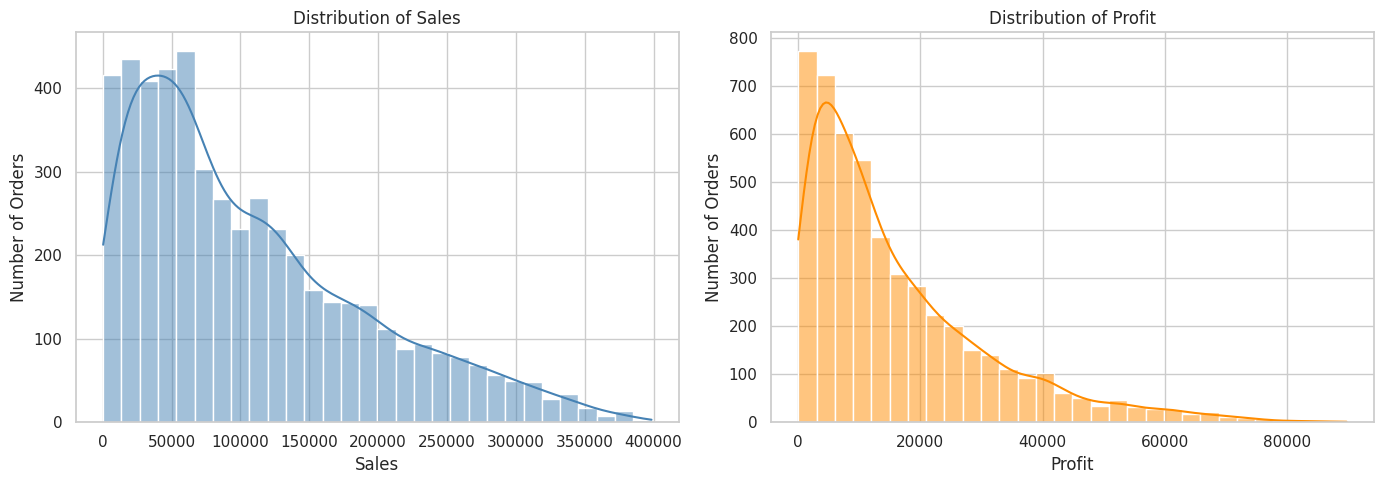

Sales median: 83080.32 | Sales mean: 106733.2
Profit median: 11108.53 | Profit mean: 15941.75


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["Sales"], bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Number of Orders")
sns.histplot(df["Profit"], bins=30, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Distribution of Profit")
axes[1].set_xlabel("Profit")
axes[1].set_ylabel("Number of Orders")
plt.tight_layout()
plt.show()
print("Sales median:", round(df["Sales"].median(), 2), "| Sales mean:", round(df["Sales"].mean(), 2))
print("Profit median:", round(df["Profit"].median(), 2), "| Profit mean:", round(df["Profit"].mean(), 2))

### Question: How many orders are in each category?

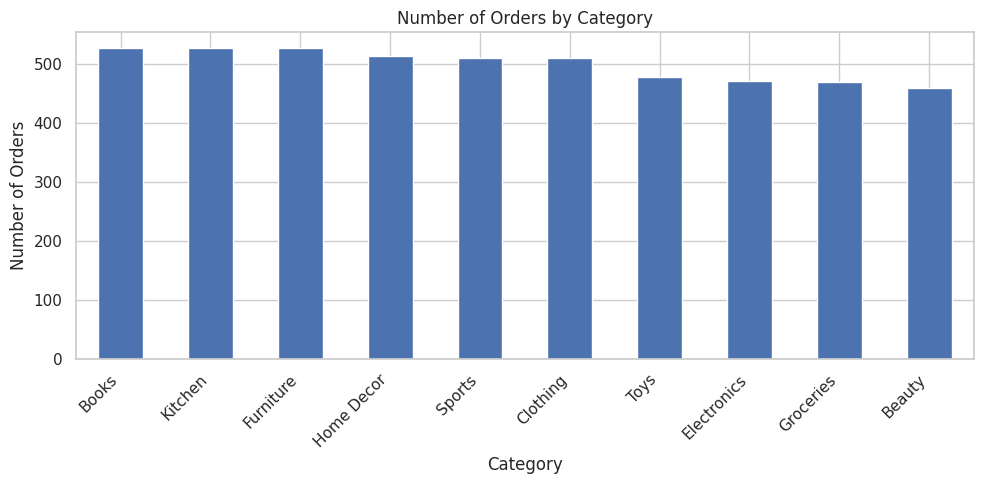

,Order Count
Category,
Books,528
Kitchen,528
Furniture,527
Home Decor,515
Sports,511
Clothing,511
Toys,478
Electronics,472
Groceries,470


In [18]:
category_counts = df["Category"].value_counts().sort_values(ascending=False)
ax = category_counts.plot(kind="bar", figsize=(10, 5))
ax.set_title("Number of Orders by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(category_counts.to_frame("Order Count"))

### Question: Which payment method is most used?

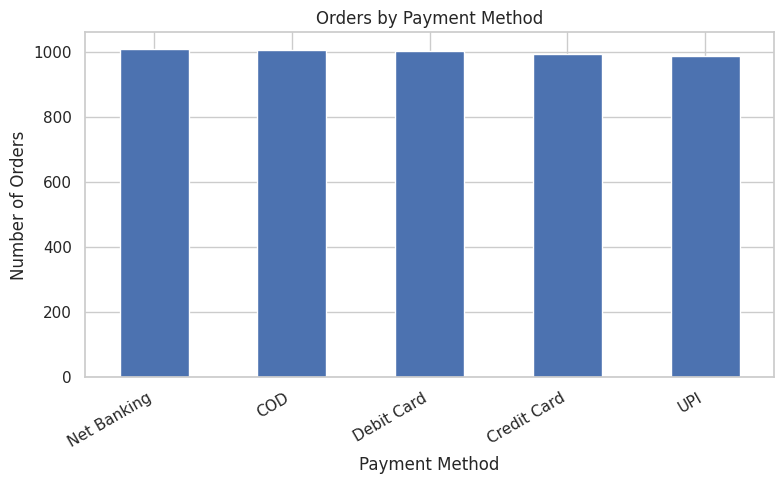

Most used payment method: Net Banking with 1010 orders


In [19]:
payment_counts = df["Payment Mode"].value_counts().sort_values(ascending=False)
ax = payment_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title("Orders by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print("Most used payment method:", payment_counts.idxmax(), "with", int(payment_counts.max()), "orders")

### Question: Which discount values are most common?

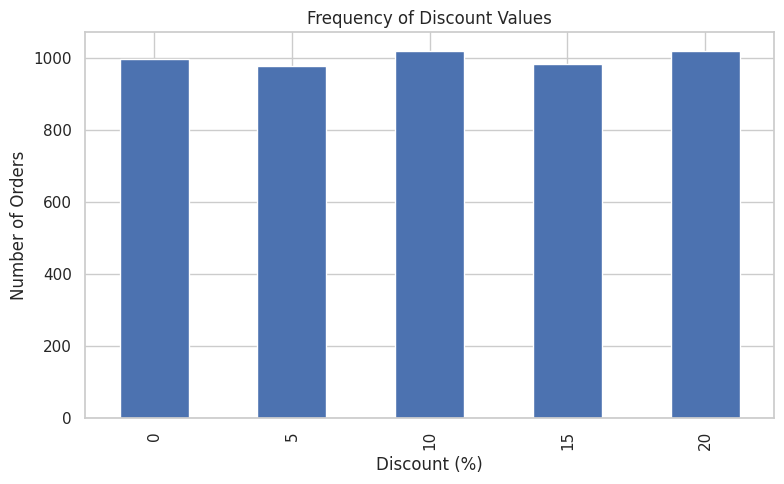

,Order Count
Discount,
0,998
5,978
10,1020
15,983
20,1021


In [20]:
discount_counts = df["Discount"].value_counts().sort_index()
ax = discount_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title("Frequency of Discount Values")
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Number of Orders")
plt.tight_layout()
plt.show()
display(discount_counts.to_frame("Order Count"))

## 6.2 Bivariate Analysis

### Question: How do sales and profit compare?

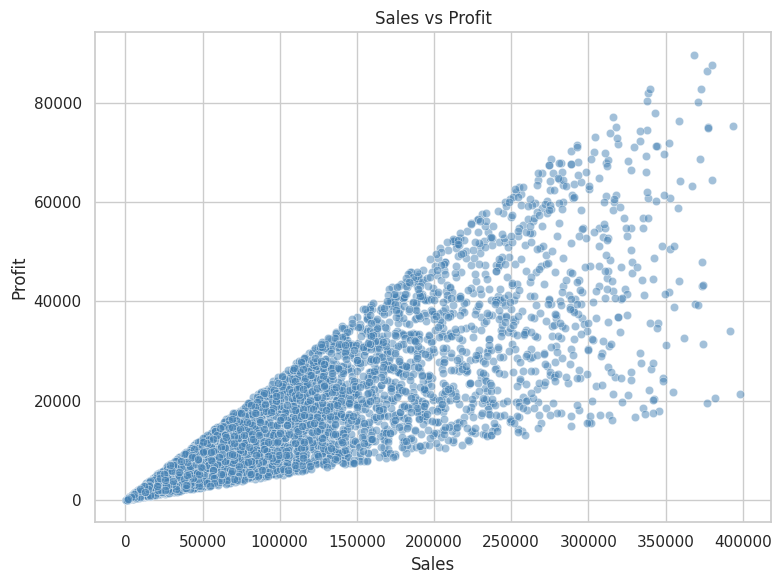

Correlation between Sales and Profit: 0.849


In [21]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Sales", y="Profit", alpha=0.5, color="steelblue")
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()
print("Correlation between Sales and Profit:", round(df["Sales"].corr(df["Profit"]), 3))

### Question: How does discount relate to profit?

,Discount,Average_Profit,Total_Profit,Order_Count
0,0,17301.211122,17266608.70,998
1,5,17442.927331,17059182.93,978
2,10,16237.786882,16562542.62,1020
3,15,14828.028087,14575951.61,983
4,20,13951.468217,14244449.05,1021


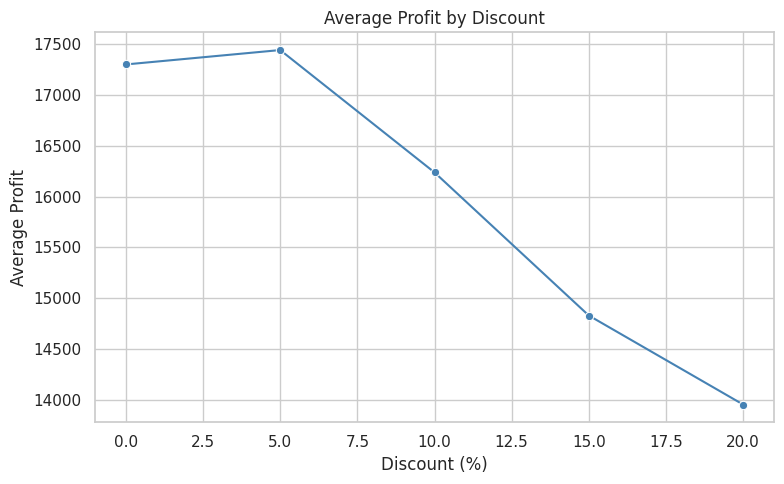

In [22]:
profit_by_discount = df.groupby("Discount", as_index=False).agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Order_Count=("Order ID", "nunique")
).sort_values("Discount")
display(profit_by_discount)
plt.figure(figsize=(8, 5))
sns.lineplot(data=profit_by_discount, x="Discount", y="Average_Profit", marker="o", color="steelblue")
plt.title("Average Profit by Discount")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.tight_layout()
plt.show()

### Question: How do regions compare by total sales?

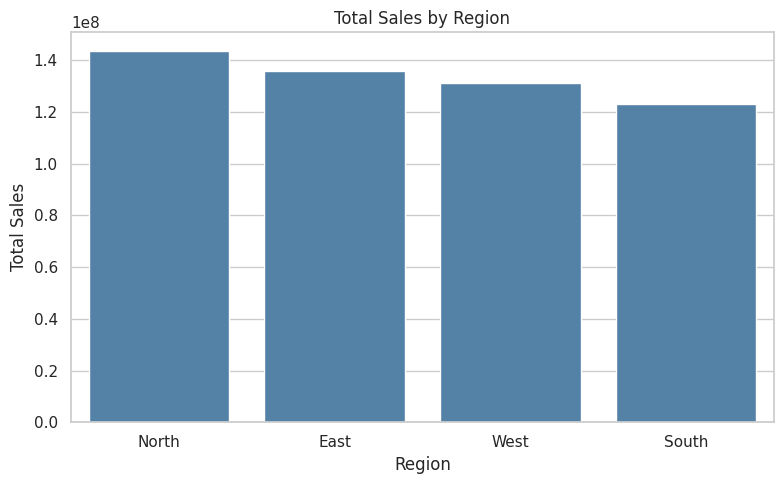

,Region,Sales
1,North,1.435782e+08
0,East,1.358116e+08
3,West,1.310460e+08
2,South,1.232302e+08


In [23]:
plt.figure(figsize=(8, 5))
sns.barplot(data=sales_by_region, x="Region", y="Sales", color="steelblue")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()
display(sales_by_region)

### Question: How does average profit vary by category?

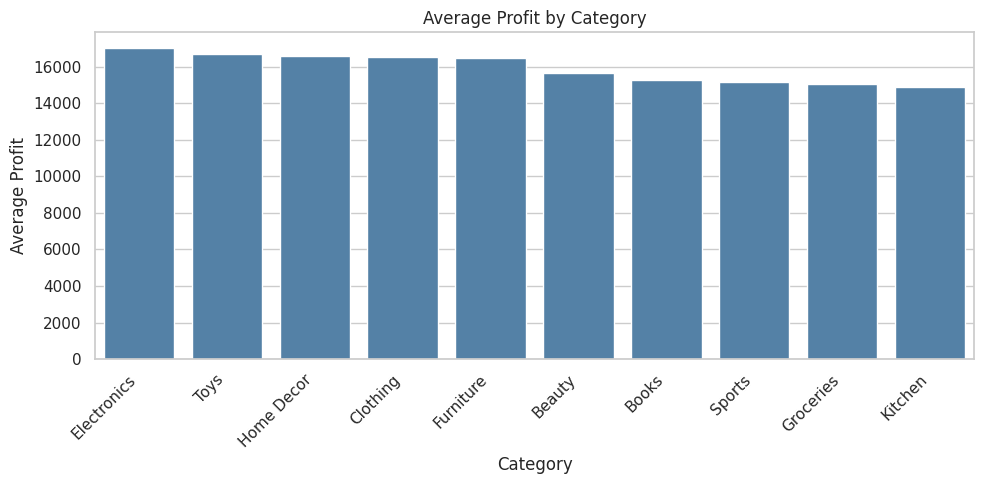

,Category,Profit
3,Electronics,17038.419237
9,Toys,16708.936067
6,Home Decor,16615.236777
2,Clothing,16527.887065
4,Furniture,16495.421309
0,Beauty,15681.382761
1,Books,15295.972140
8,Sports,15145.655656
5,Groceries,15053.899234
7,Kitchen,14923.434261


In [24]:
average_profit_by_category = df.groupby("Category", as_index=False)["Profit"].mean().sort_values("Profit", ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=average_profit_by_category, x="Category", y="Profit", color="steelblue")
plt.title("Average Profit by Category")
plt.xlabel("Category")
plt.ylabel("Average Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(average_profit_by_category)

### Question: How does quantity relate to sales?

,Quantity,Average_Sales,Total_Sales,Order_Count
0,1,36191.181618,3.691501e+07,1020
1,2,72077.508615,7.027557e+07,975
2,3,105642.632485,1.058539e+08,1002
3,4,143134.290078,1.471421e+08,1028
4,5,177927.672051,1.734795e+08,975


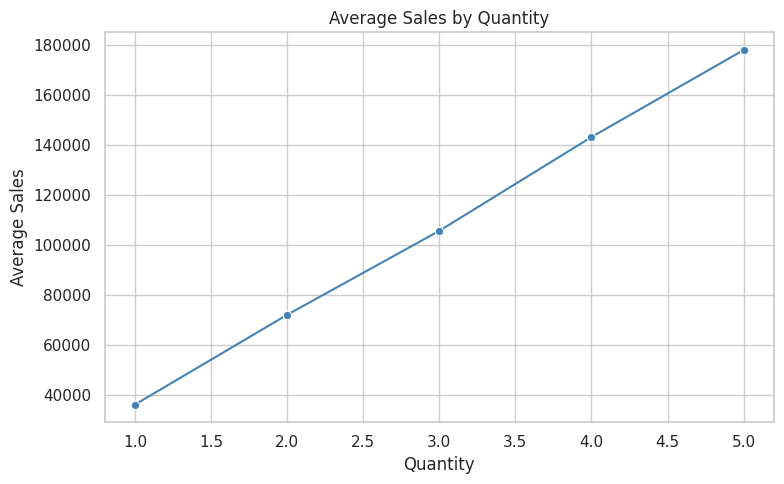

In [25]:
sales_by_quantity = df.groupby("Quantity", as_index=False).agg(
    Average_Sales=("Sales", "mean"),
    Total_Sales=("Sales", "sum"),
    Order_Count=("Order ID", "nunique")
).sort_values("Quantity")
display(sales_by_quantity)
plt.figure(figsize=(8, 5))
sns.lineplot(data=sales_by_quantity, x="Quantity", y="Average_Sales", marker="o", color="steelblue")
plt.title("Average Sales by Quantity")
plt.xlabel("Quantity")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

## 6.3 Multivariate Analysis

### Question: How do category sales compare across regions?

Region,East,North,South,West
Category,,,,
Beauty,12790403.80,13984910.85,12292234.10,11735860.95
Books,14173354.80,15441895.30,12948754.30,12368638.60
Clothing,13684994.15,15930578.90,13261557.80,12176777.45
Electronics,15165897.55,14439593.55,11880847.80,11101545.05
Furniture,13090179.45,15085776.75,11575306.65,16895925.05
Groceries,12088346.60,14357007.65,9931549.50,11506199.40
Home Decor,15589662.00,17286752.95,12083972.05,12272835.35
Kitchen,12724395.80,10781078.15,13399212.00,17323216.35
Sports,12964689.30,13754083.95,12687812.90,12662811.10


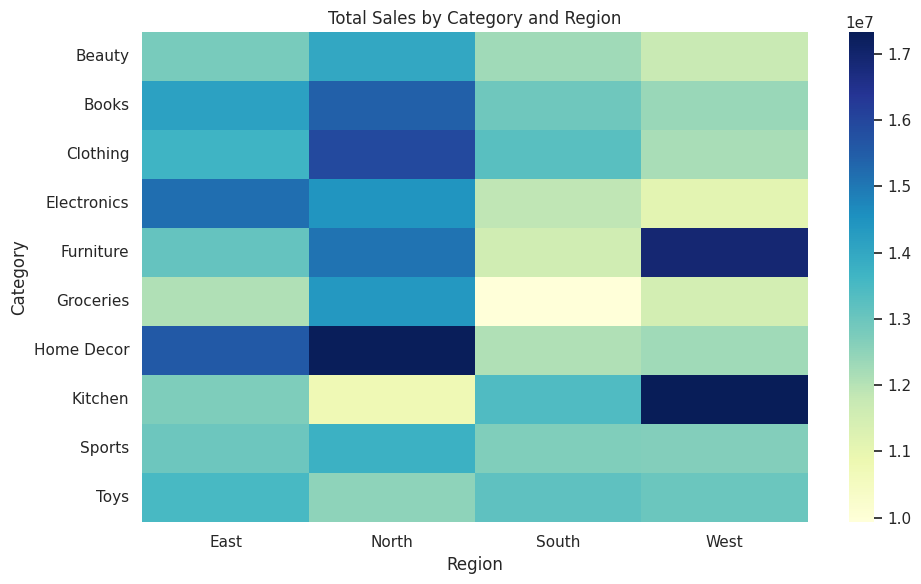

In [26]:
category_region_sales = df.pivot_table(index="Category", columns="Region", values="Sales", aggfunc="sum", fill_value=0)
display(category_region_sales)
plt.figure(figsize=(10, 6))
sns.heatmap(category_region_sales, cmap="YlGnBu", fmt=",.0f", annot=False)
plt.title("Total Sales by Category and Region")
plt.xlabel("Region")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Question: Which categories generate the most profit in the top five cities by total profit?

Top five cities by total profit: ['Lucknow', 'Guwahati', 'Bangalore', 'Chandigarh', 'Jaipur']


City,Bangalore,Chandigarh,Guwahati,Jaipur,Lucknow
Category,,,,,
Beauty,432761.27,309886.34,601666.95,413302.46,328617.11
Books,508715.92,385389.20,392534.33,398440.24,666053.59
Clothing,672593.63,429295.16,630104.83,483898.19,422975.10
Electronics,483341.01,415868.58,551807.29,531154.59,499029.55
Furniture,410995.13,481482.45,551891.83,440557.95,451734.12
Groceries,302030.84,538832.31,337817.72,432652.79,417608.16
Home Decor,449529.61,602324.54,576126.51,508229.05,675566.27
Kitchen,407553.85,371631.79,248961.09,325326.01,322578.54
Sports,369613.82,351852.86,278404.36,341765.45,430644.12


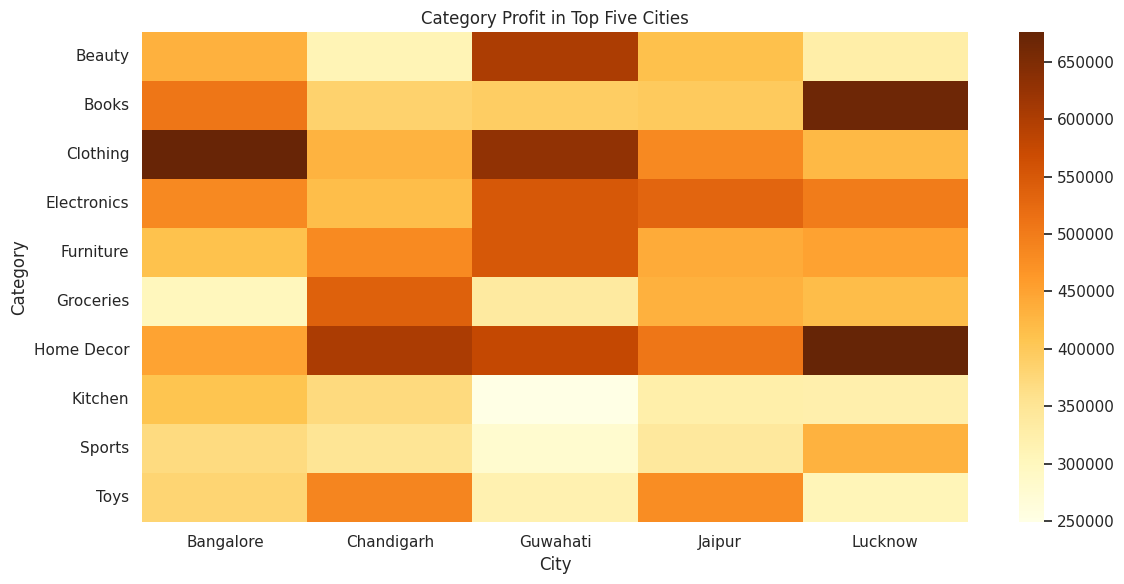

In [27]:
top_five_cities = profit_by_city.head(5)["City"].tolist()
top_city_category_profit = (
    df[df["City"].isin(top_five_cities)]
    .pivot_table(index="Category", columns="City", values="Profit", aggfunc="sum", fill_value=0)
)
print("Top five cities by total profit:", top_five_cities)
display(top_city_category_profit)
plt.figure(figsize=(12, 6))
sns.heatmap(top_city_category_profit, cmap="YlOrBr", annot=False)
plt.title("Category Profit in Top Five Cities")
plt.xlabel("City")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Question: How does discount relate to profit within each category?

,Category,Discount,Average_Profit,Order_Count
0,Beauty,0,20003.960674,89
1,Beauty,5,16715.229252,107
2,Beauty,10,15009.875000,90
3,Beauty,15,15572.126629,89
4,Beauty,20,10679.364941,85
5,Books,0,18348.621230,122
6,Books,5,16660.500562,89
7,Books,10,16853.636667,102
8,Books,15,12565.081351,111
9,Books,20,11934.249808,104


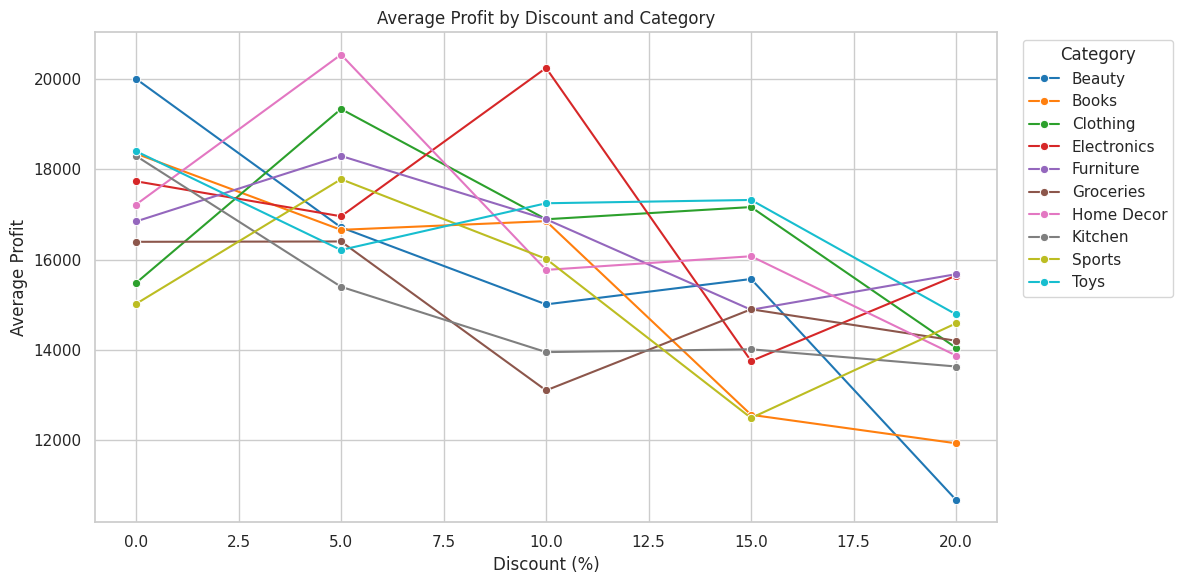

In [28]:
category_discount_profit = df.groupby(["Category", "Discount"], as_index=False).agg(
    Average_Profit=("Profit", "mean"),
    Order_Count=("Order ID", "nunique")
)
display(category_discount_profit)
plt.figure(figsize=(12, 6))
sns.lineplot(data=category_discount_profit, x="Discount", y="Average_Profit", hue="Category", marker="o", palette="tab10")
plt.title("Average Profit by Discount and Category")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Question: What are the sales trends over time for each category?

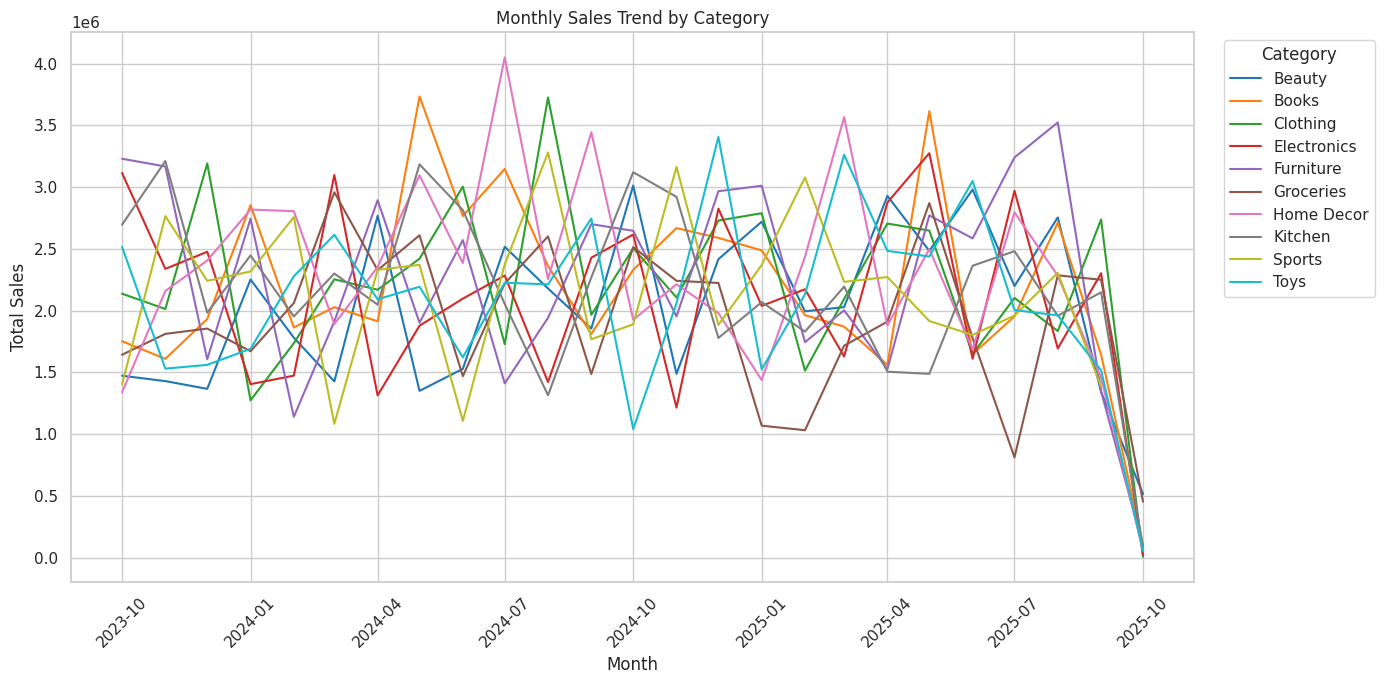

,Month,Category,Sales
0,2023-10-01,Beauty,1473219.30
1,2023-10-01,Books,1752863.85
2,2023-10-01,Clothing,2137876.95
3,2023-10-01,Electronics,3115241.80
4,2023-10-01,Furniture,3230578.15
5,2023-10-01,Groceries,1643055.75
6,2023-10-01,Home Decor,1339434.70
7,2023-10-01,Kitchen,2696194.70
8,2023-10-01,Sports,1401994.45
9,2023-10-01,Toys,2517062.55


In [29]:
monthly_category_sales = (
    df.assign(Month=df["Order Date"].dt.to_period("M").dt.to_timestamp())
      .groupby(["Month", "Category"], as_index=False)["Sales"].sum()
)
plt.figure(figsize=(14, 7))
sns.lineplot(data=monthly_category_sales, x="Month", y="Sales", hue="Category", palette="tab10")
plt.title("Monthly Sales Trend by Category")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(monthly_category_sales.head(10))

## 7. Business Insights

The following code calculates the headline findings directly from the cleaned dataset so the conclusions are not manually guessed.

In [30]:
best_sales_category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
best_profit_region = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
best_profit_city = df.groupby("City")["Profit"].sum().sort_values(ascending=False)
most_used_payment = df["Payment Mode"].value_counts()
best_order_count_category = df["Category"].value_counts()
discount_average_profit = df.groupby("Discount")["Profit"].mean().sort_values(ascending=False)

print(f"Highest total sales category: {best_sales_category.index[0]} ({best_sales_category.iloc[0]:,.2f})")
print(f"Highest total profit region: {best_profit_region.index[0]} ({best_profit_region.iloc[0]:,.2f})")
print(f"Highest total profit city: {best_profit_city.index[0]} ({best_profit_city.iloc[0]:,.2f})")
print(f"Most-used payment method: {most_used_payment.index[0]} ({most_used_payment.iloc[0]} orders)")
print(f"Category with most orders: {best_order_count_category.index[0]} ({best_order_count_category.iloc[0]} orders)")
print(f"Discount level with highest average profit: {discount_average_profit.index[0]}% ({discount_average_profit.iloc[0]:,.2f} average profit)")
print(f"Overall total sales: {df['Sales'].sum():,.2f}")
print(f"Overall total profit: {df['Profit'].sum():,.2f}")

Highest total sales category: Home Decor (57,233,222.35)
Highest total profit region: North (21,343,004.33)
Highest total profit city: Lucknow (4,523,681.09)
Most-used payment method: Net Banking (1010 orders)
Category with most orders: Books (528 orders)
Discount level with highest average profit: 5% (17,442.93 average profit)
Overall total sales: 533,666,024.35
Overall total profit: 79,708,734.91


## 8. Business Recommendations

Use the results above to make recommendations only where the analysis supports them:
- Prioritize inventory and merchandising reviews for categories with high order counts or sales, while checking profitability as well.
- Compare regional sales and profit together; a region with high sales is not automatically the most profitable.
- Review average profit by discount and category before changing discount policies. These are observational patterns and do not prove that discounts caused profit changes.
- Make sure the most-used payment methods remain reliable, and review payment preferences by order count as well as sales value.
- Use the monthly category trend chart to identify periods worth investigating; the dataset alone does not explain the causes of peaks or dips.

## 9. Conclusion

In [31]:
print(f"The dataset contains {len(df):,} orders and {df.shape[1]} columns.")
print(f"Observed order-date range: {df['Order Date'].min().date()} to {df['Order Date'].max().date()}.")
print(f"Total recorded sales: {df['Sales'].sum():,.2f}")
print(f"Total recorded profit: {df['Profit'].sum():,.2f}")
print("Interpret the results within the available dataset; do not infer causation from descriptive EDA alone.")

The dataset contains 5,000 orders and 14 columns.
Observed order-date range: 2023-10-04 to 2025-10-03.
Total recorded sales: 533,666,024.35
Total recorded profit: 79,708,734.91
Interpret the results within the available dataset; do not infer causation from descriptive EDA alone.


## 10. Save Final Dataset

In [32]:
output_path = "retail_sales_cleaned.csv"
df.to_csv(output_path, index=False)
print("Cleaned dataset saved to:", output_path)
print("Final shape:", df.shape)
print("Missing values after cleaning:", int(df.isna().sum().sum()))
print("Exact duplicate rows after cleaning:", int(df.duplicated().sum()))

Cleaned dataset saved to: retail_sales_cleaned.csv
Final shape: (5000, 14)
Missing values after cleaning: 0
Exact duplicate rows after cleaning: 0
